# Digital Advertising Budget Optimizer
## Notebook 03 — MapReduce (Hadoop Streaming)

**Goal:** compute the same KPIs as Notebook 02 using the MapReduce programming model on real Apache Hadoop,
prove the results match Pandas exactly, and measure how MapReduce behaves as data grows.

**How MapReduce works**
```
 CSV file ──► split 1 ──► MAP ──┐
          ──► split 2 ──► MAP ──┼──► SHUFFLE & SORT ──► REDUCE ──► output
          ──► split N ──► MAP ──┘     (group by key)       (sum)
```
- **Map**: read rows, emit `key → metrics` (e.g. `platform=Google → impressions, clicks, spend…`)
- **Shuffle & sort**: Hadoop groups all records with the same key together
- **Reduce**: add up the metrics for each key

**Setup used here:** Hadoop 3.3.6 in *standalone mode*, the real Hadoop MapReduce engine running on one machine.
The same mapper/reducer scripts run unchanged on a multi-node cluster.

**Outline**
1. Setup & data
2. Install Java + Hadoop (cached on Drive after the first run)
3. MapReduce scripts
4. Unit test with Unix pipes
5. Job 1: Platform KPIs
6. Job 2: All breakdowns in one pass + validation against Pandas
7. Optimisation: why combining matters
8. Scaling: 10K → 10M rows
9. Findings

**Requires:** Notebooks 01 and 02 completed. First run takes ~10 min (Hadoop download); later runs ~5 min.

In [1]:
# ============================================================
# 1. Setup
# ============================================================
import os, sys, shutil, time, json, re, glob, subprocess, hashlib, urllib.request
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = "ad-budget-optimizer"
if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    LOCAL_DIR = Path("/content") / PROJECT_NAME
else:
    DRIVE_DIR = LOCAL_DIR = Path.cwd() / PROJECT_NAME

SRC_DIR = DRIVE_DIR / "src"
MR_DIR = SRC_DIR / "mapreduce"                 # scripts saved to Drive (permanent)
LOCAL_MR = LOCAL_DIR / "mapreduce"             # copy Hadoop actually runs
MR_OUT = LOCAL_DIR / "mr_output"               # Hadoop job outputs
FIG_DIR, REP_DIR, BENCH_DIR = (DRIVE_DIR / "outputs" / d for d in ("figures", "reports", "benchmarks"))
for d in (MR_DIR, LOCAL_MR, MR_OUT, FIG_DIR, REP_DIR, BENCH_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))

assert (REP_DIR / "02_kpi_platform.csv").exists(), "Run Notebook 02 first (its results are used for validation)."

# Hadoop Streaming reads plain text, so this notebook uses the CSV files
SCALES = {"10k": 10_000, "100k": 100_000, "1m": 1_000_000, "10m": 10_000_000}
CSV_LOCAL = LOCAL_DIR / "data/raw/csv"
CSV_LOCAL.mkdir(parents=True, exist_ok=True)
for label in SCALES:
    src_f, dst_f = DRIVE_DIR / f"data/raw/csv/ads_{label}.csv", CSV_LOCAL / f"ads_{label}.csv"
    assert src_f.exists(), f"{src_f} missing. Run Notebook 01 first."
    if not dst_f.exists():
        t0 = time.time()
        shutil.copy(src_f, dst_f)
        print(f"Copied ads_{label}.csv to local disk ({dst_f.stat().st_size / 1e6:,.0f} MB, {time.time() - t0:.0f}s)")

MAP_SLOTS = os.cpu_count()      # parallel map tasks = CPU cores
print(f"Ready. CPU cores: {MAP_SLOTS}")

Mounted at /content/drive
Copied ads_10k.csv to local disk (1 MB, 0s)
Copied ads_100k.csv to local disk (9 MB, 0s)
Copied ads_1m.csv to local disk (87 MB, 1s)
Copied ads_10m.csv to local disk (872 MB, 12s)
Ready. CPU cores: 2


## 2. Install Java + Hadoop
Hadoop runs on Java 11. The Hadoop download (~700 MB) is saved to `ad-budget-optimizer/tools/` on Drive,
so later sessions only need to unpack it. The download is verified against Apache's official SHA-512 checksum.

In [2]:
# ============================================================
# 2. Java + Hadoop setup
# ============================================================
HADOOP_VERSION = "3.3.6"
TARBALL = f"hadoop-{HADOOP_VERSION}.tar.gz"
MIRRORS = [f"https://dlcdn.apache.org/hadoop/common/hadoop-{HADOOP_VERSION}/{TARBALL}",
           f"https://archive.apache.org/dist/hadoop/common/hadoop-{HADOOP_VERSION}/{TARBALL}"]
TOOLS_DIR = DRIVE_DIR / "tools"


def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}\n{r.stderr[-2000:]}")
    return r.stdout


def download(url, dest):
    with urllib.request.urlopen(url, timeout=60) as r, open(dest, "wb") as f:
        total, done, last = int(r.headers.get("Content-Length", 0)), 0, -1
        while chunk := r.read(1 << 20):
            f.write(chunk)
            done += len(chunk)
            if total and (pct := 100 * done // total) // 10 != last:
                last = pct // 10
                print(f"  {pct:3d}%  ({done / 1e6:,.0f} MB)")


def verify_sha512(path, url):
    try:
        expected = re.search(r"[0-9a-fA-F]{128}", urllib.request.urlopen(url + ".sha512", timeout=30).read().decode()).group(0)
    except Exception:
        print("  (checksum file unavailable, skipping verification)")
        return
    h = hashlib.sha512()
    with open(path, "rb") as f:
        while chunk := f.read(1 << 24):
            h.update(chunk)
    if h.hexdigest().lower() != expected.lower():
        raise ValueError("Checksum mismatch: download is corrupted")
    print("  SHA-512 checksum verified")


def setup_hadoop():
    # Java 11
    jvm = sorted(glob.glob("/usr/lib/jvm/java-11-openjdk*"))
    if not jvm:
        print("Installing Java 11 (~1 min)...")
        sh("apt-get update -qq && apt-get install -y -qq openjdk-11-jdk-headless > /dev/null")
        jvm = sorted(glob.glob("/usr/lib/jvm/java-11-openjdk*"))
    java_home = jvm[0]

    # Hadoop
    hadoop_home = Path("/content") / f"hadoop-{HADOOP_VERSION}"
    if not hadoop_home.exists():
        TOOLS_DIR.mkdir(exist_ok=True)
        cached = TOOLS_DIR / TARBALL
        if not cached.exists():
            local_tar = Path("/content") / TARBALL
            for url in MIRRORS:
                try:
                    print(f"Downloading {url}")
                    download(url, local_tar)
                    verify_sha512(local_tar, url)
                    break
                except Exception as e:
                    print(f"  failed: {e}")
            else:
                raise RuntimeError("Could not download Hadoop from any mirror")
            print("Caching Hadoop on Drive for future sessions...")
            shutil.copy(local_tar, cached)
        else:
            local_tar = cached
            print("Using Hadoop cached on Drive")
        print("Unpacking...")
        sh(f"tar -xzf '{local_tar}' -C /content")
    return java_home, hadoop_home


USE_HADOOP = False
try:
    if IN_COLAB:
        JAVA_HOME, HADOOP_HOME = setup_hadoop()
    else:   # outside Colab: use an existing Hadoop install if there is one
        JAVA_HOME, HADOOP_HOME = os.environ.get("JAVA_HOME", ""), Path(os.environ.get("HADOOP_HOME", "/nonexistent"))
    os.environ["JAVA_HOME"] = str(JAVA_HOME)
    os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
    os.environ["PATH"] = f"{HADOOP_HOME}/bin:{JAVA_HOME}/bin:" + os.environ["PATH"]
    HADOOP_BIN = str(HADOOP_HOME / "bin/hadoop")
    STREAMING_JAR = glob.glob(f"{HADOOP_HOME}/share/hadoop/tools/lib/hadoop-streaming-*.jar")[0]
    print(sh(f"{HADOOP_BIN} version").splitlines()[0], "| Java:", JAVA_HOME)
    USE_HADOOP = True
except Exception as e:
    print("⚠️ Hadoop is not available:", str(e)[:300])

ENGINE = f"Hadoop {HADOOP_VERSION} (standalone)" if USE_HADOOP else "Unix-pipe simulation"
if not USE_HADOOP:
    print("⚠️ FALLBACK: jobs will run as  cat | mapper | sort | reducer  (same scripts, same data flow, "
          "but not Hadoop). Fix the error above and re-run this cell to use real Hadoop.")
print("Engine:", ENGINE)

Installing Java 11 (~1 min)...
    0%  (1 MB)
   10%  (73 MB)
   20%  (147 MB)
   30%  (219 MB)
   40%  (293 MB)
   50%  (366 MB)
   60%  (438 MB)
   70%  (512 MB)
   80%  (585 MB)
   90%  (657 MB)
  100%  (730 MB)
  SHA-512 checksum verified
Caching Hadoop on Drive for future sessions...
Unpacking...
Hadoop 3.3.6 | Java: /usr/lib/jvm/java-11-openjdk-amd64
Engine: Hadoop 3.3.6 (standalone)


## 3. MapReduce scripts
Three small Python scripts, saved to `src/mapreduce/` on Drive:

| Script | Role |
|---|---|
| `mapper.py` | Production mapper. Uses **in-mapper combining**: totals are accumulated in memory and each key is emitted once per input split |
| `mapper_naive.py` | Textbook mapper: emits one record per row. Used only for the optimisation comparison in section 7 |
| `reducer.py` | Sums metrics per key. Its output format equals its input format, so it doubles as the **combiner** |

KPI ratios (CTR, ROAS…) are **not** computed inside MapReduce. MapReduce produces the sums (the heavy part),
then the shared `kpis.add_kpis()` turns them into KPIs, so every engine uses identical formulas.

In [3]:
%%writefile {MR_DIR}/mapper.py
#!/usr/bin/env python3
"""
mapper.py: Hadoop Streaming mapper with IN-MAPPER COMBINING.

Instead of emitting one record per input row, the mapper keeps running totals
in a dictionary and emits each key once, at the end of its input split.
That shrinks the shuffle from millions of records to a few hundred.

Usage : python3 mapper.py <dimensions>     e.g.  platform  |  platform,age  |  all
Input : CSV  date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
Output: <dimension>=<value> TAB impressions TAB clicks TAB spend TAB conversions TAB revenue
"""
import sys

FIELDS = "date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device".split(",")
IDX = {name: i for i, name in enumerate(FIELDS)}
ALL_DIMS = ["platform", "campaign", "age", "gender", "city", "device", "date|platform"]


def make_key_fn(dim):
    cols = [IDX[c] for c in dim.split("|")]
    if len(cols) == 1:
        i = cols[0]
        return lambda f: dim + "=" + f[i]
    return lambda f: dim + "=" + "|".join(f[i] for i in cols)


def main():
    arg = sys.argv[1] if len(sys.argv) > 1 else "platform"
    dims = ALL_DIMS if arg == "all" else arg.split(",")
    key_fns = [make_key_fn(d) for d in dims]
    totals, bad = {}, 0

    for line in sys.stdin:
        f = line.rstrip("\r\n").split(",")
        if f[0] == "date":                       # header row
            continue
        if len(f) != len(FIELDS):                # malformed row
            bad += 1
            continue
        try:
            m = (int(f[3]), int(f[4]), float(f[5]), int(f[6]), float(f[7]))
        except ValueError:
            bad += 1
            continue
        for key_fn in key_fns:
            key = key_fn(f)
            t = totals.get(key)
            if t is None:
                totals[key] = list(m)
            else:
                t[0] += m[0]; t[1] += m[1]; t[2] += m[2]; t[3] += m[3]; t[4] += m[4]

    out = sys.stdout.write
    for key, t in totals.items():
        out(f"{key}\t{t[0]}\t{t[1]}\t{t[2]:.2f}\t{t[3]}\t{t[4]:.2f}\n")
    if bad:                                      # shows up as a Hadoop job counter
        sys.stderr.write(f"reporter:counter:AdData,MalformedRows,{bad}\n")


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/ad-budget-optimizer/src/mapreduce/mapper.py


In [4]:
%%writefile {MR_DIR}/mapper_naive.py
#!/usr/bin/env python3
"""
mapper_naive.py: textbook mapper that emits ONE record per input row (no local aggregation).
Used only to show why combiners and in-mapper combining matter.

Usage : python3 mapper_naive.py <dimension>     e.g. platform
"""
import sys

IDX = {"campaign": 1, "platform": 2, "age": 8, "gender": 9, "city": 10, "device": 11}


def main():
    dim = sys.argv[1] if len(sys.argv) > 1 else "platform"
    i = IDX[dim]
    out = sys.stdout.write
    for line in sys.stdin:
        f = line.rstrip("\r\n").split(",")
        if f[0] == "date" or len(f) != 12:
            continue
        out(f"{dim}={f[i]}\t{f[3]}\t{f[4]}\t{f[5]}\t{f[6]}\t{f[7]}\n")


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/ad-budget-optimizer/src/mapreduce/mapper_naive.py


In [5]:
%%writefile {MR_DIR}/reducer.py
#!/usr/bin/env python3
"""
reducer.py: sums the five metrics for each key.

Hadoop sorts mapper output by key, so all records for one key arrive together.
Output format = input format, so this same script also works as a COMBINER.
"""
import sys


def emit(key, t):
    sys.stdout.write(f"{key}\t{t[0]}\t{t[1]}\t{t[2]:.2f}\t{t[3]}\t{t[4]:.2f}\n")


def main():
    current, t = None, None
    for line in sys.stdin:
        key, imp, clk, spd, conv, rev = line.rstrip("\r\n").split("\t")
        if key != current:
            if current is not None:
                emit(current, t)
            current, t = key, [0, 0, 0.0, 0, 0.0]
        t[0] += int(imp); t[1] += int(clk); t[2] += float(spd); t[3] += int(conv); t[4] += float(rev)
    if current is not None:
        emit(current, t)


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/ad-budget-optimizer/src/mapreduce/reducer.py


In [7]:
shutil.copytree(MR_DIR, LOCAL_MR, dirs_exist_ok=True)
for f in LOCAL_MR.glob("*.py"):
    f.chmod(0o755)
print("Scripts ready:", sorted(p.name for p in LOCAL_MR.glob("*.py")))

Scripts ready: ['mapper.py', 'mapper_naive.py', 'reducer.py']


## 4. Unit test with Unix pipes
Hadoop Streaming is equivalent to `cat input | mapper | sort | reducer`.
Testing that pipeline on the 10K file first catches bugs in seconds, before involving Hadoop.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
from IPython.display import display, Markdown
import kpis, viz
importlib.reload(kpis); importlib.reload(viz)
viz.apply_style()

test_csv = CSV_LOCAL / "ads_10k.csv"
pipe = subprocess.run(f"python3 {LOCAL_MR}/mapper.py platform < {test_csv} | LC_ALL=C sort | python3 {LOCAL_MR}/reducer.py",
                      shell=True, capture_output=True, text=True, check=True).stdout
mr = pd.DataFrame([l.split("\t") for l in pipe.strip().splitlines()],
                  columns=["key"] + kpis.METRICS).set_index("key")
mr.index = mr.index.str.split("=").str[1]
mr = mr.astype({"impressions": int, "clicks": int, "spend": float, "conversions": int, "revenue": float})

ref = pd.read_csv(test_csv).groupby("platform")[kpis.METRICS].sum()
ok = mr.index.equals(ref.index) and np.allclose(mr.values, ref.values, rtol=1e-12, atol=0.01)
display(mr)
print("✅ Unit test passed: pipeline output matches Pandas" if ok else "❌ Unit test FAILED")
assert ok

,impressions,clicks,spend,conversions,revenue
key,,,,,
Facebook,40119987,484704,5995544.56,9373,19509728.76
Google,4102549,121949,3690792.13,4531,15863313.03
Instagram,26286024,261346,4743242.87,5048,17045645.84
TikTok,40178318,318427,2803689.81,2956,7189346.44
YouTube,20389244,81395,2013395.05,861,3423617.33


✅ Unit test passed: pipeline output matches Pandas


## 5. Running jobs
`run_job()` submits a Hadoop Streaming job, times it, and collects Hadoop's job counters
(records read, records emitted by the map phase, records shuffled to the reducer, and so on).

In [9]:
def parse_counters(log):
    """Pull 'Name=value' job counters out of Hadoop's log output."""
    return {k.strip(): int(v) for k, v in re.findall(r"^\s+([A-Za-z][A-Za-z ]+)=(\d+)\s*$", log, re.M)}


def _simulate(input_csv, out_dir, mapper_cmd, combiner):
    """Fallback when Hadoop is unavailable: the same data flow with Unix tools."""
    tmp = out_dir / "_tmp"
    tmp.mkdir(parents=True)
    run = lambda c: subprocess.run(c, shell=True, check=True, executable="/bin/bash")
    reducer = f"python3 {LOCAL_MR}/reducer.py"
    t0 = time.time()
    run(f"{mapper_cmd} < {input_csv} > {tmp}/map.txt")
    run(f"LC_ALL=C sort -S 25% {tmp}/map.txt > {tmp}/sorted.txt")
    reduce_in = f"{tmp}/sorted.txt"
    if combiner:
        run(f"{reducer} < {tmp}/sorted.txt > {tmp}/combined.txt")
        reduce_in = f"{tmp}/combined.txt"
    run(f"{reducer} < {reduce_in} > {out_dir}/part-00000")
    secs = time.time() - t0
    count = lambda p: int(subprocess.run(f"wc -l < {p}", shell=True, capture_output=True, text=True).stdout)
    counters = {"Map output records": count(f"{tmp}/map.txt"), "Reduce input records": count(reduce_in),
                "Reduce output records": count(out_dir / "part-00000")}
    shutil.rmtree(tmp)
    (out_dir / "_SUCCESS").touch()
    return secs, counters


def run_job(name, label, dims="platform", mapper="mapper.py", combiner=False, quiet=False):
    """Run one MapReduce job on ads_<label>.csv. Returns a dict of timing + counters."""
    input_csv, out_dir = CSV_LOCAL / f"ads_{label}.csv", MR_OUT / name
    shutil.rmtree(out_dir, ignore_errors=True)
    mapper_cmd = f"python3 {LOCAL_MR}/{mapper} {dims}"
    if USE_HADOOP:
        # Local mode: scripts are referenced by absolute path.
        # On a multi-node cluster you would ship them with  -files mapper.py,reducer.py
        cmd = [HADOOP_BIN, "jar", STREAMING_JAR,
               "-D", f"mapreduce.job.name={name}",
               "-D", f"mapreduce.local.map.tasks.maximum={MAP_SLOTS}",
               "-D", "mapreduce.job.reduces=1",
               "-input", f"file://{input_csv}",
               "-output", f"file://{out_dir}",
               "-mapper", mapper_cmd,
               "-reducer", f"python3 {LOCAL_MR}/reducer.py"]
        if combiner:
            cmd += ["-combiner", f"python3 {LOCAL_MR}/reducer.py"]
        t0 = time.time()
        r = subprocess.run(cmd, capture_output=True, text=True)
        secs = time.time() - t0
        if r.returncode != 0 or not (out_dir / "_SUCCESS").exists():
            print(r.stderr[-4000:])
            raise RuntimeError(f"Hadoop job '{name}' failed (log above)")
        counters = parse_counters(r.stderr)
    else:
        secs, counters = _simulate(input_csv, out_dir, mapper_cmd, combiner)
    if not quiet:
        print(f"[{name}] {SCALES[label]:,} rows in {secs:.1f}s  "
              f"| map output records: {counters.get('Map output records', 'n/a'):,}")
    return {"job": name, "dataset": label, "rows": SCALES[label], "seconds": round(secs, 2),
            "map_output_records": counters.get("Map output records"),
            "reduce_input_records": counters.get("Reduce input records"),
            "malformed_rows": counters.get("MalformedRows", 0), "engine": ENGINE}


def read_output(name):
    """Load a job's part-* files into a DataFrame: dimension, value, metrics."""
    rows = []
    for part in sorted((MR_OUT / name).glob("part-*")):
        with open(part) as fh:
            for line in fh:
                key, imp, clk, spd, conv, rev = line.rstrip("\n").split("\t")
                dim, value = key.split("=", 1)
                rows.append((dim, value, int(imp), int(clk), float(spd), int(conv), float(rev)))
    return pd.DataFrame(rows, columns=["dimension", "value"] + kpis.METRICS)


def kpi_from_mr(res, dim):
    t = res[res.dimension == dim].set_index("value")[kpis.METRICS]
    t.index.name = dim
    return kpis.add_kpis(t)

print("Helpers ready | engine:", ENGINE)

Helpers ready | engine: Hadoop 3.3.6 (standalone)


## 6. Job 1: Platform KPIs on 10M rows

In [ ]:
job1 = run_job("platform_10m", "10m", dims="platform")
plat_mr = kpi_from_mr(read_output("platform_10m"), "platform").reindex(viz.PLATFORM_ORDER)
plat_mr.to_csv(REP_DIR / "03_mr_kpi_platform.csv")
display(kpis.view(plat_mr).sort_values("ROAS", ascending=False))

## 7. Job 2: Every breakdown in one pass + validation
One job computes platform, campaign, age, gender, city, device **and** daily-by-platform totals in a single read of the data.
The mapper emits several keys per row (`platform=Google`, `city=Lahore`, `date|platform=2026-03-20|Google` …).
One pass over 10M rows is much cheaper than seven separate jobs.

Every result is then checked against the Pandas results from Notebook 02.

In [10]:
job2 = run_job("all_dims_10m", "10m", dims="all")
res = read_output("all_dims_10m")
print(res.dimension.value_counts().rename("groups").to_frame().T.to_string())

# Pandas reference results from Notebook 02
refs = {d: pd.read_csv(REP_DIR / f"02_kpi_{d}.csv", index_col=0)
        for d in ["platform", "campaign", "age", "gender", "city", "device"]}
daily_ref = pd.read_parquet(DRIVE_DIR / "data/processed/daily_platform_10m.parquet")
daily_ref.index = daily_ref.date.dt.strftime("%Y-%m-%d") + "|" + daily_ref.platform.astype(str)
refs["date|platform"] = daily_ref


def validate(dim):
    ref = refs[dim][kpis.METRICS].copy()
    ref.index = ref.index.astype(str)
    mr = res[res.dimension == dim].set_index("value")[kpis.METRICS]
    same_keys = set(mr.index) == set(ref.index)
    mr = mr.reindex(ref.index)
    ints = ["impressions", "clicks", "conversions"]
    ints_exact = bool((mr[ints].values == ref[ints].values).all())
    max_diff = float(np.abs(mr[["spend", "revenue"]].values - ref[["spend", "revenue"]].values).max())
    money_ok = np.allclose(mr[["spend", "revenue"]], ref[["spend", "revenue"]], rtol=1e-9, atol=0.5)
    return {"breakdown": dim, "groups": len(ref), "same_groups": same_keys, "counts_exact": ints_exact,
            "max_money_diff_Rs": round(max_diff, 4),
            "status": "PASS" if same_keys and ints_exact and money_ok else "FAIL"}

validation = pd.DataFrame([validate(d) for d in refs]).set_index("breakdown")
validation.to_csv(REP_DIR / "03_validation_vs_pandas.csv")
display(validation)
n_pass = (validation.status == "PASS").sum()
print(f"{n_pass}/{len(validation)} breakdowns match Pandas" + (" ✅" if n_pass == len(validation) else " ❌"))

for d in ["campaign", "age", "gender", "city", "device"]:
    kpi_from_mr(res, d).to_csv(REP_DIR / f"03_mr_kpi_{d}.csv")

[all_dims_10m] 10,000,000 rows in 103.6s  | map output records: 49,140
dimension  date|platform  campaign  city  age  platform  device  gender
groups              1825        40    10    5         5       3       2


,groups,same_groups,counts_exact,max_money_diff_Rs,status
breakdown,,,,,
platform,5,True,True,0.0,PASS
campaign,40,True,True,0.0,PASS
age,5,True,True,0.0,PASS
gender,2,True,True,0.0,PASS
city,10,True,True,0.0,PASS
device,3,True,True,0.0,PASS
date|platform,1825,True,True,0.0,PASS


7/7 breakdowns match Pandas ✅


Money totals can differ by a few paisa: Pandas and MapReduce add up millions of decimal numbers in a different order,
and floating-point rounding depends on order. All counts match exactly.

## 8. Optimisation: why combining matters
The shuffle (moving map output to the reducers) is usually the most expensive part of MapReduce on a real cluster,
because it crosses the network. Three versions of the same platform job on 1M rows:

| Version | What the mapper sends to the shuffle |
|---|---|
| Naive | 1 record per input row |
| Naive + combiner | Hadoop pre-sums each map task's output before the shuffle |
| In-mapper combining | the mapper sums in memory and emits each key once |

[opt_naive] 1,000,000 rows in 18.4s  | map output records: 1,000,000
[opt_combiner] 1,000,000 rows in 13.2s  | map output records: 1,000,000
[opt_inmapper] 1,000,000 rows in 11.5s  | map output records: 15


,seconds,map_output_records,reduce_input_records
version,,,
Naive,18.39,1000000,1000000
Naive + combiner,13.21,1000000,15
In-mapper combining,11.54,15,15


All three versions produce identical results ✅


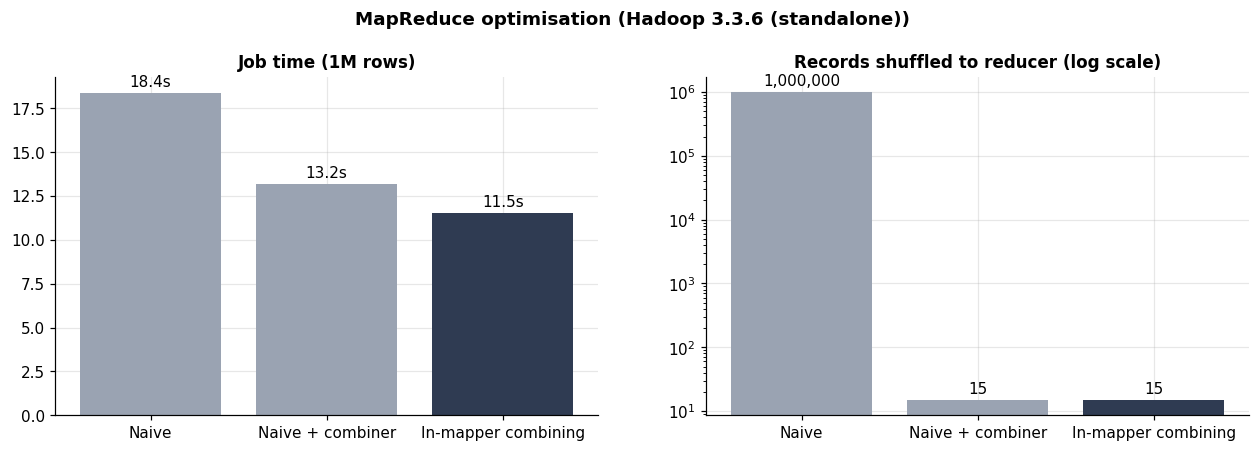

In [11]:
opt = pd.DataFrame([
    {**run_job("opt_naive", "1m", mapper="mapper_naive.py"), "version": "Naive"},
    {**run_job("opt_combiner", "1m", mapper="mapper_naive.py", combiner=True), "version": "Naive + combiner"},
    {**run_job("opt_inmapper", "1m", mapper="mapper.py"), "version": "In-mapper combining"},
]).set_index("version")
opt.to_csv(BENCH_DIR / "03_mapreduce_optimisation.csv")
display(opt[["seconds", "map_output_records", "reduce_input_records"]])

# All three must give identical answers
outs = [read_output(n).set_index("value")[kpis.METRICS] for n in ["opt_naive", "opt_combiner", "opt_inmapper"]]
assert all(np.allclose(outs[0].loc[o.index], o, rtol=1e-9, atol=0.5) for o in outs[1:]), "Versions disagree!"
print("All three versions produce identical results ✅")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
b = ax[0].bar(opt.index, opt.seconds, color=[viz.NEUTRAL, viz.NEUTRAL, viz.ACCENT])
ax[0].bar_label(b, fmt="%.1fs", padding=2)
ax[0].set_title("Job time (1M rows)")
shuffle = opt.reduce_input_records.astype(float)
b = ax[1].bar(opt.index, shuffle, color=[viz.NEUTRAL, viz.NEUTRAL, viz.ACCENT])
ax[1].bar_label(b, labels=[f"{v:,.0f}" for v in shuffle], padding=2)
ax[1].set_yscale("log")
ax[1].set_title("Records shuffled to reducer (log scale)")
fig.suptitle(f"MapReduce optimisation ({ENGINE})", fontweight="bold", y=1.03)
viz.save(fig, FIG_DIR, "03_mapreduce_optimisation"); plt.show()

## 9. Scaling: 10K → 10M rows
The same platform job on every dataset size. Watch two things:
the **fixed overhead** (Hadoop needs several seconds to start a job even for tiny data)
and the **throughput** (rows per second) once data is large enough to keep it busy.

[scale_10k] 10,000 rows in 5.5s  | map output records: 5
[scale_100k] 100,000 rows in 5.5s  | map output records: 5
[scale_1m] 1,000,000 rows in 10.2s  | map output records: 15
[scale_10m] 10,000,000 rows in 43.5s  | map output records: 130


,rows,seconds,rows_per_sec,engine
dataset,,,,
10k,10000,5.50,1818.0,Hadoop 3.3.6 (standalone)
100k,100000,5.51,18149.0,Hadoop 3.3.6 (standalone)
1m,1000000,10.21,97943.0,Hadoop 3.3.6 (standalone)
10m,10000000,43.46,230097.0,Hadoop 3.3.6 (standalone)


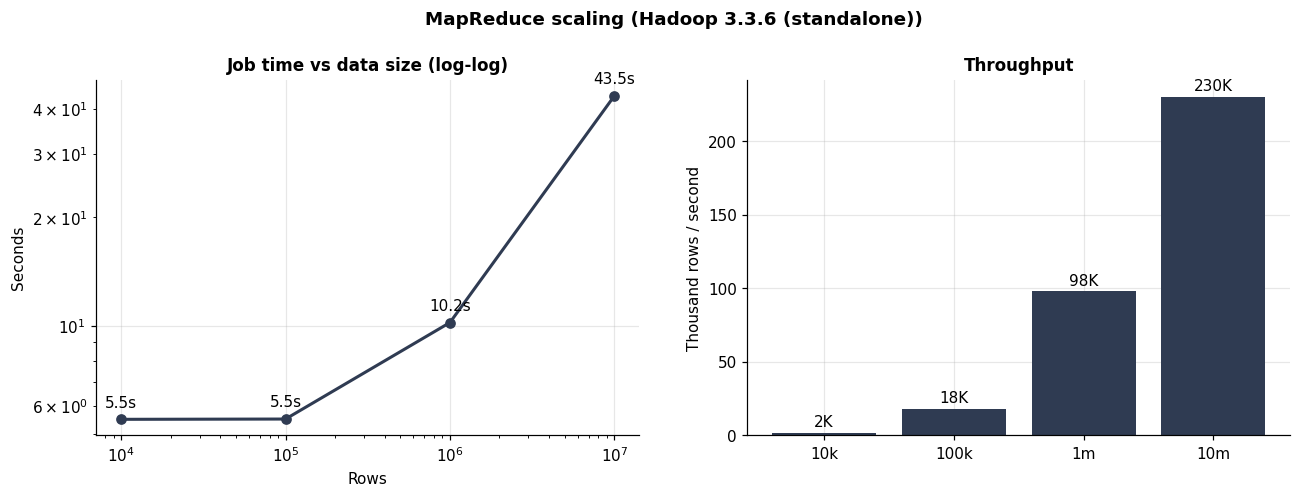

In [12]:
scaling = pd.DataFrame([run_job(f"scale_{label}", label) for label in SCALES]).set_index("dataset")
scaling["rows_per_sec"] = (scaling.rows / scaling.seconds).round(0)
scaling.to_csv(BENCH_DIR / "03_mapreduce_scaling.csv")
display(scaling[["rows", "seconds", "rows_per_sec", "engine"]])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(scaling.rows, scaling.seconds, "o-", color=viz.ACCENT, lw=2)
for lbl, r in scaling.iterrows():
    ax[0].annotate(f"{r.seconds:.1f}s", (r.rows, r.seconds), textcoords="offset points", xytext=(0, 8), ha="center")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Rows"); ax[0].set_ylabel("Seconds"); ax[0].set_title("Job time vs data size (log-log)")
b = ax[1].bar(scaling.index, scaling.rows_per_sec / 1e3, color=viz.ACCENT)
ax[1].bar_label(b, fmt="%.0fK", padding=2)
ax[1].set_ylabel("Thousand rows / second"); ax[1].set_title("Throughput")
fig.suptitle(f"MapReduce scaling ({ENGINE})", fontweight="bold", y=1.03)
viz.save(fig, FIG_DIR, "03_mapreduce_scaling"); plt.show()

## 10. Findings

In [13]:
naive, best = opt.loc["Naive"], opt.loc["In-mapper combining"]
small, large = scaling.iloc[0], scaling.iloc[-1]
overhead_note = ("Small jobs are dominated by Hadoop's fixed start-up cost, so MapReduce only pays off on large data."
                 if small.seconds >= 2 else "Time grows roughly in line with data size.")
findings = f"""
**Engine:** {ENGINE}, {MAP_SLOTS} parallel map slot(s)

1. **Correctness:** {n_pass} of {len(validation)} breakdowns ({validation.groups.sum():,} groups in total) match Pandas.
   Counts are identical; money totals differ by at most Rs. {validation.max_money_diff_Rs.max():.2f} (floating-point rounding).
2. **One pass, many answers:** a single job produced all seven breakdowns in {job2['seconds']:.0f}s,
   instead of reading 10M rows seven times.
3. **Combining matters:** in-mapper combining cut the records sent to the reducer from
   {naive.reduce_input_records:,.0f} to {best.reduce_input_records:,.0f}, and job time from {naive.seconds:.1f}s to {best.seconds:.1f}s.
   On a real cluster, the shuffle crosses the network, so this saving is even larger.
4. **Scaling:** {small.rows:,.0f} rows took {small.seconds:.1f}s and {large.rows:,.0f} rows took {large.seconds:.1f}s
   ({large.rows / small.rows:,.0f}x the data, {large.seconds / small.seconds:,.0f}x the time),
   peaking at {large.rows_per_sec:,.0f} rows/second. {overhead_note}
"""
(REP_DIR / "03_findings.md").write_text(findings)
display(Markdown(findings))


**Engine:** Hadoop 3.3.6 (standalone), 2 parallel map slot(s)

1. **Correctness:** 7 of 7 breakdowns (1,890 groups in total) match Pandas.
   Counts are identical; money totals differ by at most Rs. 0.00 (floating-point rounding).
2. **One pass, many answers:** a single job produced all seven breakdowns in 104s,
   instead of reading 10M rows seven times.
3. **Combining matters:** in-mapper combining cut the records sent to the reducer from
   1,000,000 to 15, and job time from 18.4s to 11.5s.
   On a real cluster, the shuffle crosses the network, so this saving is even larger.
4. **Scaling:** 10,000 rows took 5.5s and 10,000,000 rows took 43.5s
   (1,000x the data, 8x the time),
   peaking at 230,097 rows/second. Small jobs are dominated by Hadoop's fixed start-up cost, so MapReduce only pays off on large data.


## ✅ Notebook 03 complete

**Saved:** MapReduce scripts in `src/mapreduce/`, KPI tables and validation in `outputs/reports/03_*`,
timings in `outputs/benchmarks/03_*`, charts in `outputs/figures/03_*`.

**Next: Notebook 04, Spark (PySpark).** The same KPIs with Spark DataFrames, validated against Pandas the same way.